# Rossmann Sales Forecasting
## 04 — Model Training & Test Forecasts

- Processed features, preprocessing, **two 48-day folds**, and final log-XGBoost configuration.
- Compared **Linear Regression** with **XGBoost (log sales)**


### 1. Load the processed data

- Reused feature files from Notebook 03; did not recalculate or modify historical features.

In [4]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

processed_dir = Path("../data/processed")
output_dir = Path("../outputs")
model_dir = Path("../models")

train = pd.read_csv(processed_dir / "train_features.csv",
                    parse_dates=["Date", "OriginDate"], dtype={"StateHoliday": "string"})
test = pd.read_csv(processed_dir / "test_features.csv",
                   parse_dates=["Date", "OriginDate"], dtype={"StateHoliday": "string"})

if not train.drop(columns="Sales").columns.equals(test.columns):
    raise ValueError("Train and test features do not match")
if not test["HorizonDay"].between(1, 48).all():
    raise ValueError("Test dates fall outside the 48-day horizon")

feature_columns = test.columns.drop(["Date", "OriginDate"]).tolist()
print("Train:", train.shape, "Test:", test.shape)

Train: (1017209, 28) Test: (41088, 27)


### 2. Prepare preprocessing and models

- Treated `Store` and other codes as categories.
- The pipeline fits imputers and encoding **inside each training fold**.
- `TransformedTargetRegressor` applies `log1p` for training and reverses it automatically during prediction.

In [5]:
categorical = ["Store", "StoreType", "Assortment", "StateHoliday", "PromoInterval"]
numeric = [col for col in feature_columns if col not in categorical]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

models = {
    "Linear Regression": LinearRegression(),
    "XGBoost (log sales)": TransformedTargetRegressor(
        regressor=XGBRegressor(
            n_estimators=250, max_depth=6, learning_rate=0.07,
            subsample=0.9, colsample_bytree=0.9,
            objective="reg:squarederror", tree_method="hist",
            random_state=42, n_jobs=-1
        ),
        func=np.log1p,
        inverse_func=np.expm1
    )
}

### 3. Evaluate both models

- Used two expanding-window folds of 48 calendar days each.
- Fitted the entire pipeline again for each fold; no validation observations were used to fit preprocessing.

In [6]:
dates = pd.DatetimeIndex(train["Date"].unique()).sort_values()
if not dates.equals(pd.date_range(dates.min(), dates.max())):
    raise ValueError("Training calendar has missing dates")

results = []
for name, model in models.items():
    for fold, (past, future) in enumerate(TimeSeriesSplit(n_splits=2, test_size=48).split(dates), 1):
        origin = dates[past[-1]]
        start, end = dates[future[0]], dates[future[-1]]
        training = train["Date"].le(origin) & train["Sales"].gt(0)
        validation_period = train["Date"].between(start, end)
        validation = validation_period & train["Sales"].gt(0)

        if not train.loc[validation_period, "OriginDate"].eq(origin).all():
            raise ValueError(f"Wrong forecast origin in fold {fold}")

        pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model))
        ])
        pipeline.fit(train.loc[training, feature_columns], train.loc[training, "Sales"])

        actual = train.loc[validation, "Sales"].to_numpy()
        predicted = np.clip(pipeline.predict(train.loc[validation, feature_columns]), 0, None)
        rmspe = np.sqrt(np.mean(((actual - predicted) / actual) ** 2)) * 100
        results.append([name, fold, rmspe,
                        mean_absolute_error(actual, predicted),
                        np.sqrt(mean_squared_error(actual, predicted))])
        print(f"{name} | Fold {fold} | RMSPE: {rmspe:.2f}%")

fold_results = pd.DataFrame(results, columns=["Model", "Fold", "RMSPE (%)", "MAE", "RMSE"])
summary = fold_results.groupby("Model")[["RMSPE (%)", "MAE", "RMSE"]].mean()
base = summary.loc["Linear Regression", "RMSPE (%)"]
best = summary.loc["XGBoost (log sales)", "RMSPE (%)"]

print(f"\nRMSPE reduction vs Linear Regression: {(base - best) / base * 100:.2f}%")
display(summary.round(2))

Linear Regression | Fold 1 | RMSPE: 20.78%
Linear Regression | Fold 2 | RMSPE: 21.78%
XGBoost (log sales) | Fold 1 | RMSPE: 14.91%
XGBoost (log sales) | Fold 2 | RMSPE: 14.60%

RMSPE reduction vs Linear Regression: 30.67%


,RMSPE (%),MAE,RMSE
Model,,,
Linear Regression,21.28,1047.69,1449.22
XGBoost (log sales),14.75,786.74,1114.95


### 4. Fit final model and save it

- Refit the chosen XGBoost model using all available positive-sales training rows.
- Kept the preprocessing and model together in a single saved pipeline.

In [7]:
final_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", clone(models["XGBoost (log sales)"]))
])
positive_sales = train["Sales"].gt(0)
final_pipeline.fit(train.loc[positive_sales, feature_columns], train.loc[positive_sales, "Sales"])

model_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(final_pipeline, model_dir / "rossmann_log_xgboost_simple.joblib")
print("Final model saved")

Final model saved


### 5. Forecast the Kaggle test records

- Converted predictions to original sales units automatically; do **not** apply `expm1` again.
- Assigned zero sales to known closed days.
- Saved a separate submission so the original Kaggle-scored file remains untouched.

In [8]:
predictions = np.clip(final_pipeline.predict(test[feature_columns]), 0, None)
predictions = np.where(test["Open"].eq(0), 0, predictions)

forecast = test[["Store", "Date", "HorizonDay", "Open"]].copy()
forecast["PredictedSales"] = np.round(predictions, 2)

raw_test = pd.read_csv("../data/raw/test.csv", parse_dates=["Date"])
submission = raw_test[["Id", "Store", "Date"]].merge(
    forecast[["Store", "Date", "PredictedSales"]],
    on=["Store", "Date"], how="left", validate="one_to_one"
)[["Id", "PredictedSales"]].rename(columns={"PredictedSales": "Sales"})

if submission["Sales"].isna().any() or len(submission) != len(raw_test):
    raise ValueError("Incomplete test predictions")

output_dir.mkdir(parents=True, exist_ok=True)
forecast.to_csv(output_dir / "test_forecasts_simple.csv", index=False)
submission.to_csv(output_dir / "submission_simple.csv", index=False)
summary.to_csv(output_dir / "model_comparison_simple.csv")
print("Test predictions:", len(submission))
display(submission)

Test predictions: 41088


,Id,Sales
0,1,4660.069824
1,2,7338.149902
2,3,10755.750000
3,4,6873.759766
4,5,7470.279785
...,...,...
41083,41084,3232.590088
41084,41085,9235.559570
41085,41086,6128.180176
41086,41087,23276.099609


### 6. Visualize one store's forecast

- Plotted predicted daily sales for a single store to illustrate the 48-day forecast.

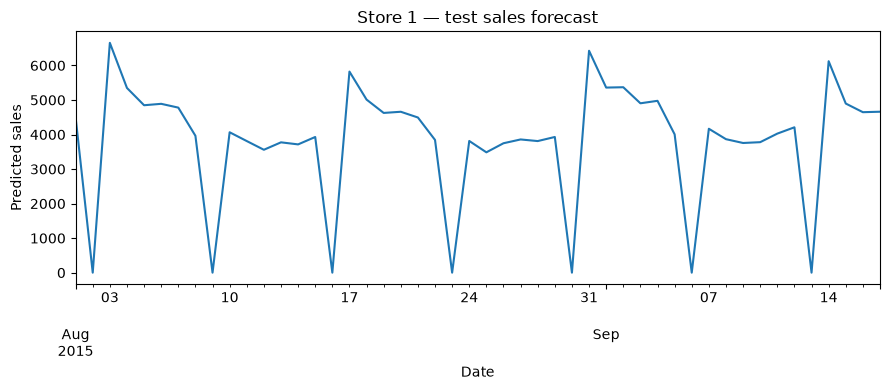

In [9]:
example_store = forecast["Store"].iloc[0]
store_forecast = forecast[forecast["Store"] == example_store].sort_values("Date")
ax = store_forecast.plot(x="Date", y="PredictedSales", figsize=(9, 4), legend=False,
                         title=f"Store {example_store} — test sales forecast")
ax.set_ylabel("Predicted sales")
plt.tight_layout()
plt.show()